In [4]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import fetch_openml

In [2]:

# Import the MNIST dataset. this might be slow  
X,y = fetch_openml('mnist_784',
 return_X_y=True)

In [4]:
n_images = X.shape[0]

# Convert data to numpy image pixel-by-pixel representation
X_images = X.to_numpy().reshape(n_images, 28, 28)

# Flatten the data so that we can apply clustering
X_flat = X_images.reshape(n_images, 28 * 28)

In [5]:
print(X.shape, X_flat.shape, X_images.shape, y.shape)
X_images[0]

(70000, 784) (70000, 784) (70000, 28, 28) (70000,)


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

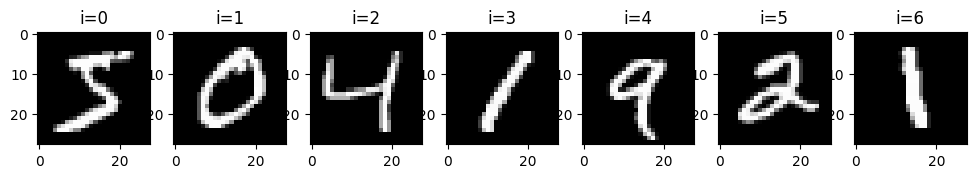

In [6]:
# plot the resulting images
plt.figure(figsize=(12, 12))
img_max = 7
for i in range(img_max):
    ax = plt.subplot(img_max, img_max, i + 1)
    plt.imshow(X_images[i,:], cmap=plt.cm.gray)
    ax.set_title(f"i={i}")
    

See if the elbow plot is useful. Is there an elbow at k = 10? This will be slow because it has to chug through a lot of images.

In [7]:
inertia = []
for k in range(7 , 14): # this is slow
    algorithm = (KMeans(n_clusters = k ,init='k-means++', n_init = 10 ,max_iter=100, 
                        tol=0.0001,  random_state= 111  , algorithm='elkan') )
    algorithm.fit(X_flat)
    inertia.append(algorithm.inertia_)

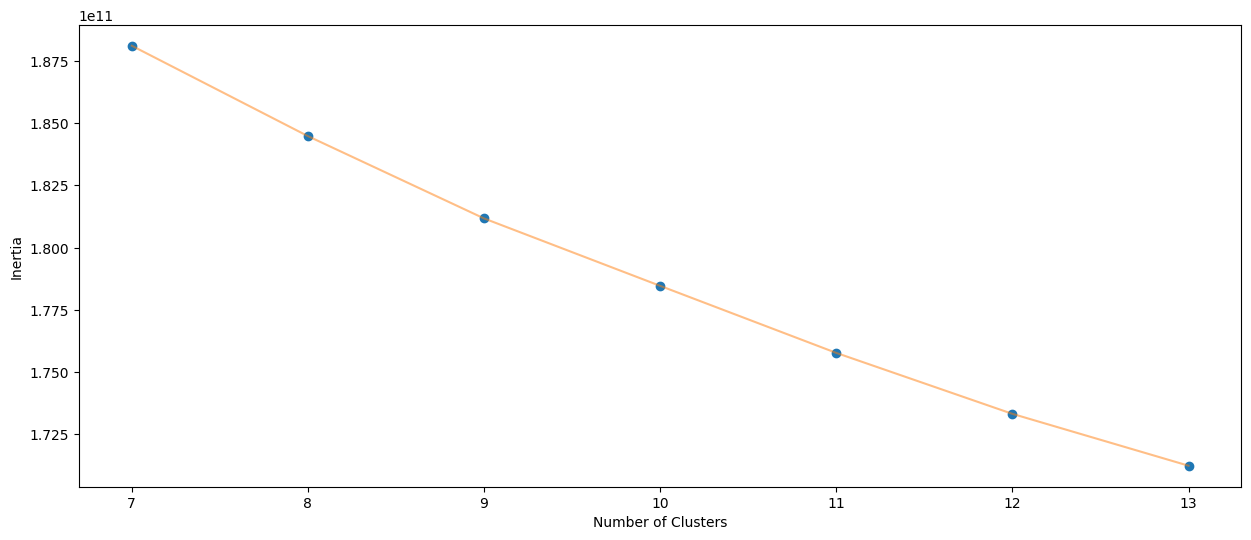

In [8]:
plt.figure(1 , figsize = (15 ,6))
plt.plot(np.arange(7 , 14) , inertia , 'o')
plt.plot(np.arange(7 , 14) , inertia , '-' , alpha = 0.5)
plt.xlabel('Number of Clusters') , plt.ylabel('Inertia')
plt.show()

Since k-means calculates the location of the centroid (which can be interpreted as the 'average' image), we can plot these centroids as images.

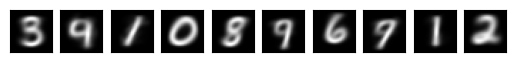

In [9]:
n_clusters = 10

algorithm = (KMeans(n_clusters = n_clusters ,init='k-means++', n_init = 10 ,max_iter=100, 
                        tol=0.0001,  random_state= 111  , algorithm='elkan') )
algorithm.fit(X_flat)
labels = algorithm.labels_
centroids = algorithm.cluster_centers_

fig, axes = plt.subplots(1, n_clusters)
n_clusters = len(np.unique(labels))

for c_i in range(n_clusters):

    # get center for cluster c_i and reshape it for plotting
    image = centroids[c_i].reshape(28,28)

    # plot the cluster centers
    axes[c_i].imshow(image, 
              cmap='grey')

    # Styling: Turn off x/y ticks
    axes[c_i].set_yticks([])
    axes[c_i].set_xticks([])



### Plotting Code
We are going to be needing this code a lot, so we'll encapsulate into a function.


This groups a sample of the images by cluster and plots them in a grid. 

In [10]:

# labels - the output of the clustering algorithm
# X_images - the original images in 28x28 pixel format
# n_clusters - the number of clusters in the clustering algorithm, such as 10 (the true value) or 13 (if you are being experimental)

def plot_images(labels, X_images, n_clusters):
    image_cluster = [[] for _ in range(n_clusters)] 
    # Collect all images that belong to each cluster. j ranges over the cluster labels (0-9) 
    img_max = 300
    for j in range(n_clusters):
        for i in range(img_max):
            if labels[i] == j:  # Only collect images that belong to the current cluster
                image_cluster[j].append(X_images[i, :])
            if len(image_cluster[j]) >= 13:  # Limit to 10 images per cluster
                break
            
    for n in range(len(image_cluster)):
        k = len(image_cluster[n])
        fig, axes = plt.subplots(1, k, figsize=(1 * k, 1), squeeze=False)
        for i, ax in enumerate(axes[0]):
            ax.imshow(image_cluster[n][i], cmap=plt.cm.gray)
            ax.set_title(f"Cluster{n}")
            ax.axis("off")
        plt.show()

The averages look decent - but how do the individual images look? This function shows samples of images in each cluster.

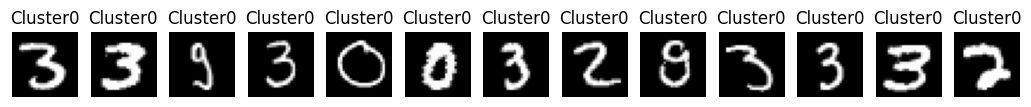

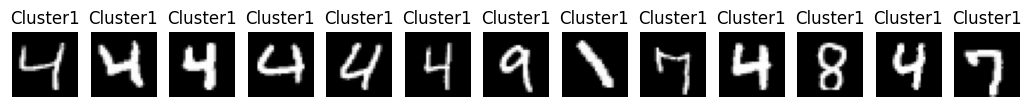

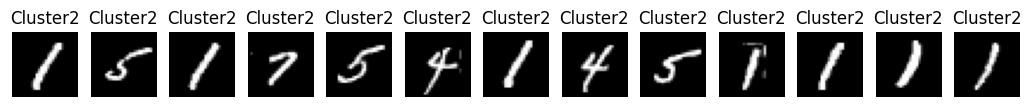

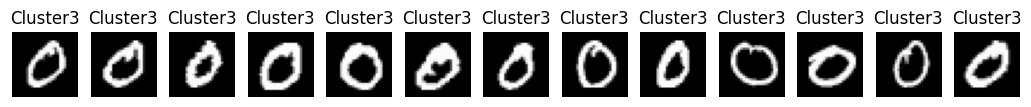

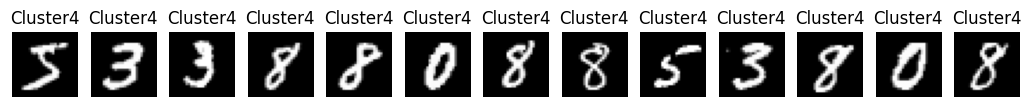

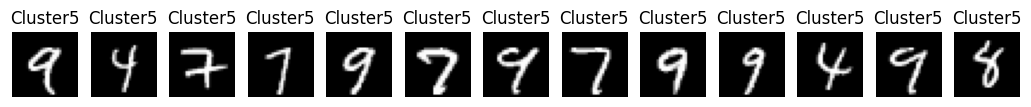

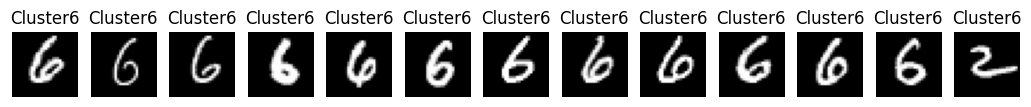

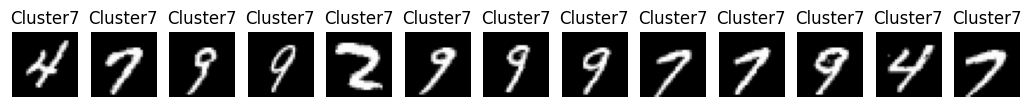

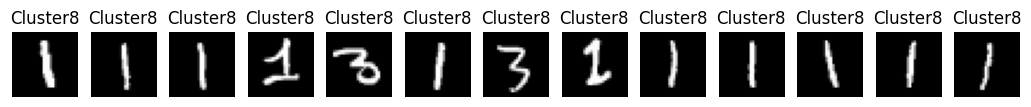

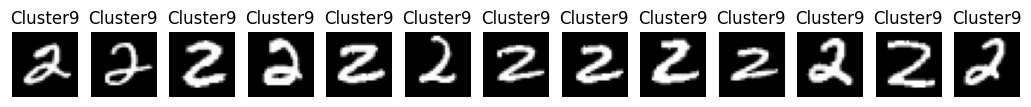

In [11]:
plot_images(labels, X_images, 10)

TODO: Repeat this process for 13 clusters instead of 10. Do the plotting of the averages and the individual images. 

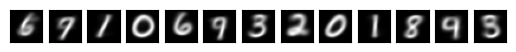

In [12]:
# your code here
n_clusters = 13

algorithm = (KMeans(n_clusters = n_clusters ,init='k-means++', n_init = 10 ,max_iter=100, 
                        tol=0.0001,  random_state= 111  , algorithm='elkan') )
algorithm.fit(X_flat)
labels = algorithm.labels_
centroids = algorithm.cluster_centers_

fig, axes = plt.subplots(1, n_clusters)
n_clusters = len(np.unique(labels))

for c_i in range(n_clusters):

    # get center for cluster c_i and reshape it for plotting
    image = centroids[c_i].reshape(28,28)

    # plot the cluster centers
    axes[c_i].imshow(image, 
              cmap='grey')

    # Styling: Turn off x/y ticks
    axes[c_i].set_yticks([])
    axes[c_i].set_xticks([])

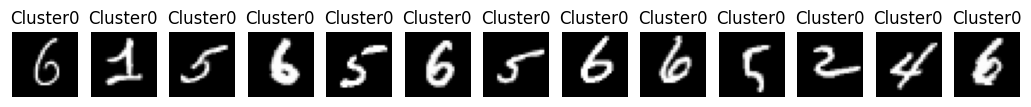

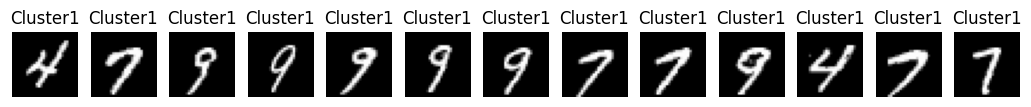

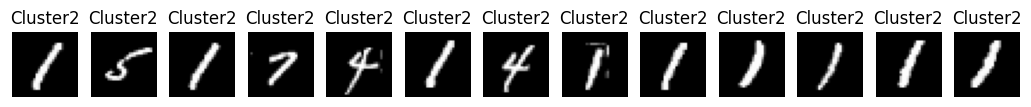

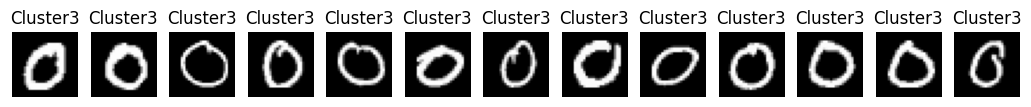

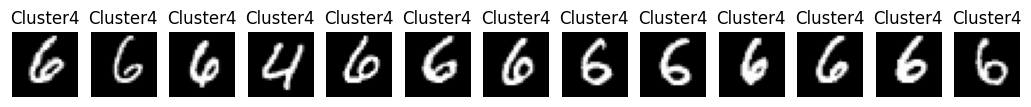

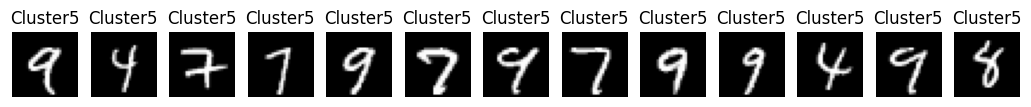

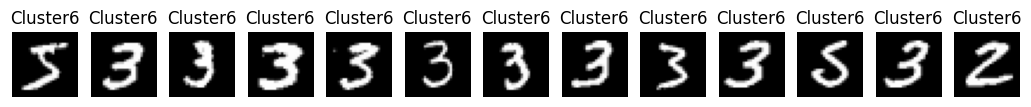

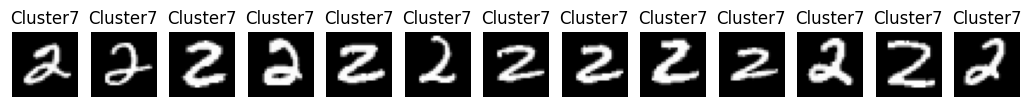

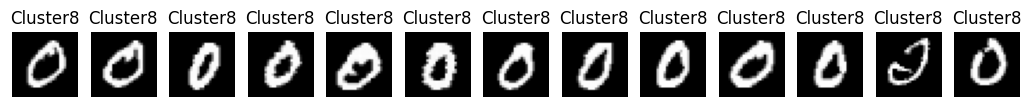

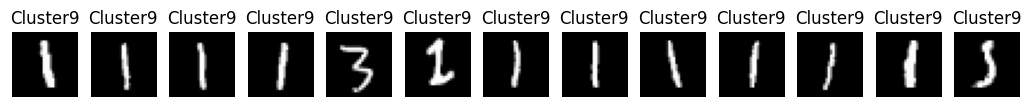

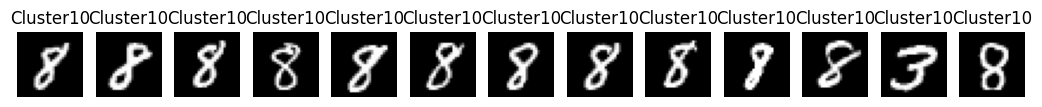

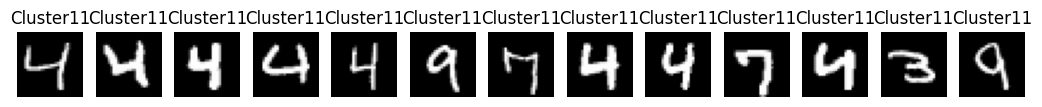

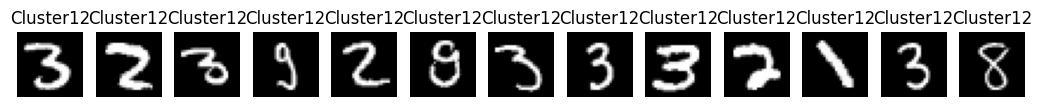

In [13]:
plot_images(labels, X_images, 13)

Does this seem to help disambiguate the difficult-to-distinguish images, or does it seem like there's still a problem?

this clustering seems to not help disambiguate the difficult-to-distinguish images, additionally, there are multiple clusters with the same number (ex. 0)

## Alternate method: BIRCH

In [3]:
from sklearn.cluster import Birch

birch_model = Birch(threshold=1.7, n_clusters=10)
birch_model.fit(X)
labels = birch_model.labels_
centroids = birch_model.subcluster_centers_
n_clusters = np.unique(labels).size

MemoryError: unable to allocate array data.

Birch does not produce averages the way that KMeans does. To visualize the results, we use PCA to reduce the dimensionality of the data to 2D. 

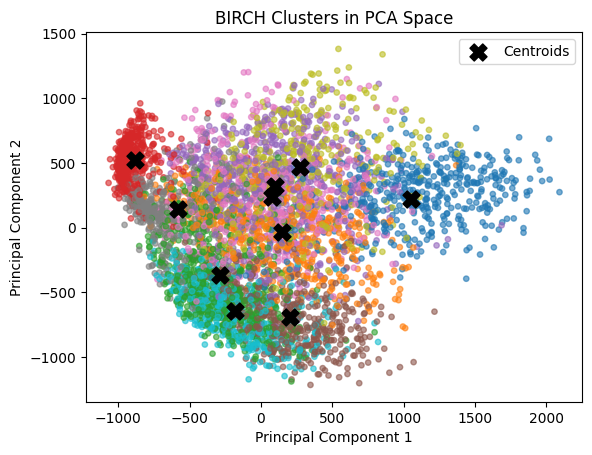

In [ ]:
from sklearn.decomposition import PCA
# Reduce dimensionality to 2D using PCA
pca = PCA(n_components=2, random_state=1)
X_pca = pca.fit_transform(X)

# Calculate the centroids of the BIRCH clusters in the 2D PCA space
centroids_pca = []
for i in range(10):
    cluster_points = X_pca[labels == i]
    if len(cluster_points) > 0:
        centroids_pca.append(cluster_points.mean(axis=0))
centroids_pca = np.array(centroids_pca)

# Plot 1: BIRCH Cluster Assignments + Centroids
scatter1 = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', s=15, alpha=0.6)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='black', marker='X', s=150, label='Centroids')
plt.title("BIRCH Clusters in PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()

plt.show()

PCA works poorly here to show separate clusters; they all run together. Here's an alternative mehtod, TSNE, which also accomplishes dimensional reduction. You should be able to see the clusters with this method.

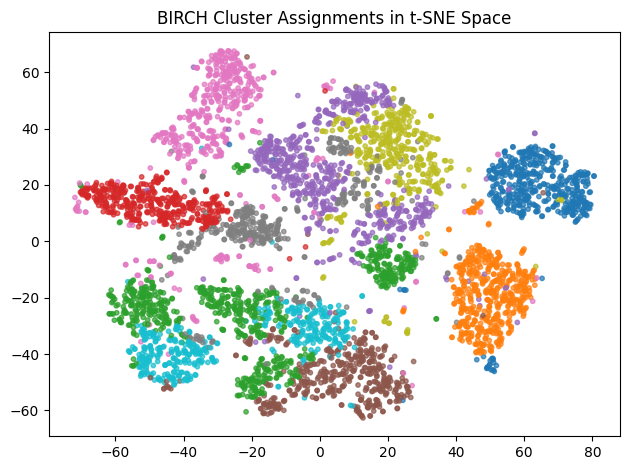

In [ ]:

from sklearn.manifold import TSNE

#  Reduce dimensions to 2D using t-SNE for visualization
tsne = TSNE(n_components=2, random_state=1)
X_2d = tsne.fit_transform(X)


# Plot BIRCH Cluster Assignments
scatter1 = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='tab10', s=10, alpha=0.7)
plt.title("BIRCH Cluster Assignments in t-SNE Space")

plt.show()

In [ ]:
image_cluster = [[] for _ in range(10)] 
# Collect all images that belong to each cluster. j ranges over the cluster labels (0-9) 
img_max = 25
for j in range(10):
    for i in range(img_max):
        if labels[i] == j:  # Only collect images that belong to the current cluster
            image_cluster[j].append(X_images[i, :])



TODO: 
1) Plot the images for the BIRCH results - one row per cluster. In a perfect world, the same number should appear in every row. But does it?

2) Write some code that evaluates the methods based on accuracy. Compare accuracy in BIRCH vs. K-means. We tried two values of the number of clusters in K-means. Neither of them worked super well, so it can be hard to compute accuracy because it isn't always obvious which cluster is "supposed" to be which number. However, you can still make some choices of mapping clusters onto digits to compute an accuracy value. You don't have to do both of the K-means; pick whichever number of clusters makes it easiest for you to map onto an accuracy value. 